## 1. Business Problem

About 1 in 5 customers churns, and the retention budget is limited, so we can't offer discounts to everyone.
Our churn model flags high-risk customers (score ≥ 0.70).

**Question:** does giving a 10% offer to these flagged customers actually reduce churn compared with doing nothing?
**Decision:** roll the offer out to high-risk customers, or don't.

## 2. Success Metric: 60-day churn rate

Share of customers with **no purchase in the 60 days after the offer** (`churned_60d`; 1 = churned).

| Property | Why this metric qualifies |
|---|---|
| **Measurable** | Binary (0/1), taken straight from purchase records, no judgement involved |
| **Attributable** | Customers are randomly assigned to offer or no offer, so the offer is the only systematic difference between groups. The window starts at exposure and is fixed in advance |
| **Sensitive / low variability** | It is the exact behaviour the offer targets, so it moves within the window. A 0/1 outcome has bounded variance, unlike revenue, which is skewed and noisy |

## 3. Hypotheses

- **H₀ (null):** the offer has no effect: churn rate (offer) = churn rate (no offer)
- **H₁ (alternative):** the offer changes churn: churn rate (offer) ≠ churn rate (no offer). We expect a reduction.

Test: two-sided two-proportion z-test.

## 4. Significance Level: α = 0.05

The chance of a **false alarm** (Type I error): concluding the offer works when it really does nothing.
We accept a 5% risk of this.

## 5. Statistical Power: 80%

If the offer truly reduces churn by at least our minimum detectable effect, we have an **80% chance of detecting it**.
The remaining 20% is the risk of **missing a real effect** (Type II error, β = 0.20).

## 2. Success Metric

**Primary: 60-day churn rate**, the share of customers with no purchase in the 60 days after the offer (`churned_60d`).
Guardrail metrics (margin, cost per saved customer) come later, once we add money.

## 3. Minimum Detectable Effect (MDE)

**MDE = the smallest real effect we care about detecting.** Here: **7 percentage points** (churn 80% → 73%).

- Why not smaller? The offer costs money, so it must save enough customers to pay for itself. A tiny reduction isn't worth acting on even if it is "statistically significant".
- Why not bigger? Then we'd miss effects that are still worth having.
- Cost of a small MDE: **halving the MDE roughly quadruples the sample size.**

| Planning input | Value |
|---|---|
| Baseline churn (control) | 80% |
| MDE (absolute) | 7 pp |
| α | 0.05 |
| Power | 80% |
| **Required sample** | to be computed in code (you should land near 575 per arm) |

## 4. Experiment Design

| Item | Choice |
|---|---|
| Population | High-risk customers (model score ≥ 0.70) |
| Unit of randomisation | Customer |
| Assignment | Random 50/50 (independent coin flip per customer) |
| Treatment | 10% offer |
| Control | No offer (business as usual) |
| Enrolment | Rolling over 6 weeks, planned sample + 10% buffer |
| Outcome window | 60 days after the offer, fixed in advance |
| Analysis | Intention-to-treat: analyse everyone in the group they were assigned to |
| Stopping rule | Fixed sample, no peeking at results and stopping early |

    High-risk customers (score ≥ 0.70)
              │ random 50/50
        ┌─────┴─────┐
     10% offer    No offer
        │            │
     60-day churn  60-day churn   →  compare

## 5. Sanity Checks (before looking at results)

### 5.1 Sample Ratio Mismatch (SRM)
**What:** the group sizes don't match the planned split (here 50/50).
**Why it matters:** a mismatch usually signals a bug in assignment or logging, and it can mean the groups are no longer comparable.
**Check:** chi-square goodness-of-fit test of observed group counts against 50/50.
**Rule:** p < 0.001 → **stop and investigate**; do not read the results.

### 5.2 Selection Bias
**What:** the two groups differ *before* the offer, so a gap in churn could come from who is in each group, not from the offer.
**Typical causes:**
- Non-random assignment (for example, a manager hand-picks who gets the offer)
- Different dropout or missing outcomes in each group
- Analysing only customers who redeemed the offer (self-selection)
- Stopping the test early when the result looks good

**Check:** compare pre-offer variables between groups (`model_score`, `avg_review_score`, `rfm_score`, `enroll_week`) using the standardised mean difference (SMD).
**Rule:** |SMD| < 0.10 → groups are comparable.

| Check | Catches |
|---|---|
| SRM | Wrong *number* of customers per group |
| Balance / selection bias | Wrong *type* of customers per group |

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats


## Dataset 
#### Dataset is Stimulated

In [4]:
df = pd.read_csv(r'C:\Users\sam\Downloads\AB_testing_data_churn_predition.csv')

In [5]:
df

,customer_id,group,model_score,avg_review_score,rfm_score,enroll_week,churned_60d
0,C04803,treatment,0.957,3.7,3,3,1
1,C03234,treatment,0.961,2.6,8,5,1
2,C07321,treatment,0.719,2.3,5,1,0
3,C05031,treatment,0.866,4.8,7,6,1
4,C01529,control,0.886,3.4,6,6,1
...,...,...,...,...,...,...,...
1261,C07525,treatment,0.867,2.7,5,4,0
1262,C05900,control,0.814,2.5,5,6,0
1263,C07034,treatment,0.818,3.0,4,1,0
1264,C00050,treatment,0.877,2.4,7,2,1


In [8]:

import pandas as pd



df = pd.read_csv(r"C:\Users\sam\Downloads\AB_testing_data_churn_predition.csv")


print("1. DATASET SHAPE")
print("-------------------------")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


print("\n2. DATA TYPES")
print("-------------------------")
print(df.dtypes)


print("\n3. MISSING VALUES")
print("-------------------------")

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

print(missing)

# --------------------------------
# 5. Duplicate records
# --------------------------------

print("\n4. DUPLICATE RECORDS")
print("-------------------------")
print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
if "customer_id" in df.columns:
    print(
        "Duplicate customer IDs:",
        df["customer_id"].duplicated().sum()
    )

# --------------------------------
# 6. Customers per group
# --------------------------------

print("\n5. CUSTOMERS PER GROUP")
print("-------------------------")

print(df["group"].value_counts())

# --------------------------------
# 7. Group percentages
# --------------------------------

print("\n6. GROUP DISTRIBUTION (%)")
print("-------------------------")

print(
    (df["group"].value_counts(normalize=True) * 100).round(2)
)

# --------------------------------
# 8. Basic statistical summary
# --------------------------------

print("\n7. NUMERICAL SUMMARY")
print("-------------------------")

print(df.describe())

# --------------------------------
# 9. Preview data
# --------------------------------

print("\n8. FIRST FIVE ROWS")
print("-------------------------")

print(df.head())


1. DATASET SHAPE
-------------------------
Rows: 1266
Columns: 7

2. DATA TYPES
-------------------------
customer_id          object
group                object
model_score         float64
avg_review_score    float64
rfm_score             int64
enroll_week           int64
churned_60d           int64
dtype: object

3. MISSING VALUES
-------------------------
                  Missing Count  Missing Percentage
customer_id                   0                 0.0
group                         0                 0.0
model_score                   0                 0.0
avg_review_score              0                 0.0
rfm_score                     0                 0.0
enroll_week                   0                 0.0
churned_60d                   0                 0.0

4. DUPLICATE RECORDS
-------------------------
Total duplicate rows: 0
Duplicate customer IDs: 0

5. CUSTOMERS PER GROUP
-------------------------
group
control      637
treatment    629
Name: count, dtype: int64

6. GROUP

In [18]:
df.duplicated(subset=["customer_id"]).sum()

np.int64(0)

## Counting The Number of Customer in the Treatment and the Control Group

In [31]:
df.groupby("group")['customer_id'].nunique()

group
control      637
treatment    629
Name: customer_id, dtype: int64

In [32]:
# Control group
control_df = df[df["group"] == "control"].copy()

# Treatment group
treatment_df = df[df["group"] == "treatment"].copy()

print("Control shape:", control_df.shape)
print("Treatment shape:", treatment_df.shape)

Control shape: (637, 7)
Treatment shape: (629, 7)


### Sample Ratio Mismatch Checking using the Chi square Goodness of fit 

In [33]:
observed = df['group'].value_counts().sort_index()   # control, treatment
expected = [len(df) / 2] * 2                          # 50/50 plan -> 633 each

chi2, p = stats.chisquare(f_obs=observed.values, f_exp=expected)

print(observed.to_dict())
print(expected)
print(f"chi2 = {chi2:.4f}, p = {p:.4f}")
print("SRM verdict:", "PASS" if p > 0.001 else "FAIL - investigate")

{'control': 637, 'treatment': 629}
[633.0, 633.0]
chi2 = 0.0506, p = 0.8221
SRM verdict: PASS


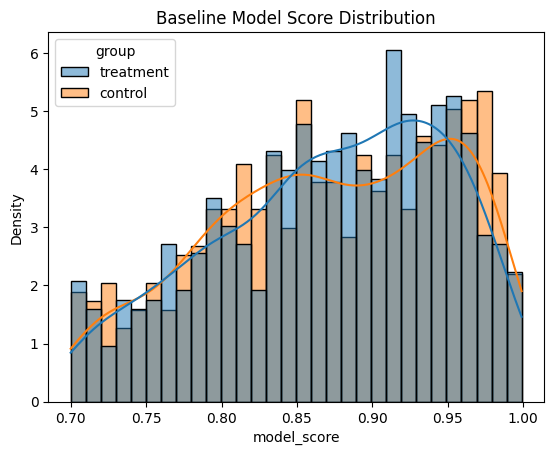

In [34]:
sns.histplot(
    data=df,
    x="model_score",
    hue="group",
    kde=True,
    bins=30,
    stat="density",
    common_norm=False
)

plt.title("Baseline Model Score Distribution")
plt.show()

In [ ]:
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep


# 1) churned count, group size, churn rate per group
summary = df.groupby('group')['churned_60d'].agg(churned='sum', n='count')
summary['churn_rate'] = summary['churned'] / summary['n']
print(summary)

treatment_group, control_group = summary.loc['treatment'], summary.loc['control']
diff = treatment_group['churn_rate'] - control_group['churn_rate']            # negative = offer reduced churn

# 2) two-sided two-proportion z-test
z, p = proportions_ztest([treatment_group['churned'], control_group['churned']], [treatment_group['n'], control_group['n']], alternative='two-sided')

# 3) 95% CI for the difference (treatment - control)
lo, hi = confint_proportions_2indep(treatment_group['churned'], treatment_group['n'], control_group['churned'], control_group['n'], method='newcomb')

print(f"\nDifference (treatment - control): {diff*100:.2f} pp")
print(f"z = {z:.3f}, p = {p:.4f}")
print(f"95% CI for the difference: [{lo*100:.2f}, {hi*100:.2f}] pp")
print("Reject H0 at 0.05?", p < 0.05)

           churned    n  churn_rate
group                              
control        488  637    0.766091
treatment      448  629    0.712242

Difference (treatment - control): -5.38 pp
z = -2.182, p = 0.0291
95% CI for the difference: [-10.19, -0.55] pp
Reject H0 at 0.05? True



# A/B Testing – Customer Churn Reduction

## 1. Objective
To evaluate whether the retention intervention reduces customer churn compared with the control group over a 60-day period.

## 2. Experiment Distribution

| Group | Customers |
|---|---:|
| Control | 637 |
| Treatment | 629 |
| Total | 1,266 |

## 3. Sample Ratio Mismatch (SRM)

Expected allocation: 50:50

- Chi-square statistic: 0.0506
- P-value: 0.8221
- Result: PASS

The experiment has no significant sample ratio mismatch.

## 4. Churn Rate Comparison

| Metric | Control | Treatment |
|---|---:|---:|
| Total customers | 637 | 629 |
| Churned customers | 488 | 448 |
| Churn rate | 76.61% | 71.22% |

**Observed churn reduction: 5.38 percentage points.**

## 5. Hypothesis Testing

- H0: There is no difference in churn rates between the two groups.
- H1: There is a difference in churn rates between the two groups.

**Test:** Two-proportion Z-test

| Metric | Result |
|---|---:|
| Z-statistic | -2.182 |
| P-value | 0.0291 |
| Significance level | 0.05 |

Since the p-value (0.0291) is less than 0.05, we reject the null hypothesis.

## 6. Confidence Interval

**95% Confidence Interval:** [-10.19, -0.55] percentage points.

The interval does not include zero, supporting a statistically significant difference between the groups.

## 7. Conclusion

The treatment group recorded a lower churn rate (71.22%) compared with the control group (76.61%).

- Absolute churn reduction: 5.38 percentage points.
- Relative churn reduction: 7.03%.
- The result is statistically significant at the 5% level.

**Business Insight:** The retention intervention shows evidence of reducing customer churn over 60 days. Further analysis of revenue retained and campaign costs is required to determine its overall profitability.
